In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import make_column_transformer
from sklearn.model_selection import LeaveOneGroupOut

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# **Read In Data**

In [2]:
df = pd.read_csv('../data/cbecs2018.csv')

# **Remove Data Missing Target Variable Information and Set Target Variable to y**
We could always impute the missing values, but this introduces more uncertainty into the model. So, we simply remove them.

In [3]:
df = df[~df['MFBTU'].isnull()]
y = df[['MFBTU']]

# **Remove Extraneous Variables**
First we move extraneous variables like imputation flags and weights. These cannot even be used since they don't really represent any values per se. 

Then we remove the variables that are basically stand ins for major fuels consumption in BTUs. Major fuels consumption in BTUs is basically the sum of the consumption in BTUs of the specific fuels like electricity or natural gas. Consumption is also represented again by consumption in non-BTU units as well as expenditures in dollars. We could theoretically use these to predict major fuels consumption in BTUs. And it would probably be incredibly accurate. But that's because they are simply parts that sum into the target variable or other ways of expressing it. We're not really interested in that. We're interested in non-fuels variables.

We also remove variables that are expressed again in another variable. There are ordinal, categorical variables that are expressed as continuous variables. We obviously want the continuous variable because it contains more information. There are binary variables that are also expressed again as continuous variables, and again, we want the continuous variable because it contains more information. Then there are variables that we don't think really mean anything to consumption.

In [4]:
#Remove Imputation Flags & Weights. These cannot be used to predict the target variable.
df = df.loc[:, ~df.columns.str.startswith('Z')] #Imputation Flag
df = df.loc[:, ~df.columns.str.contains('FINALWT+')] #Weights

In [5]:
#Remove the variables that are almost perfectly correlated with the target variable. Normally, we would want highly correlated variables.
#But these are variables for consumption in BTUs of specific fuel types as well as consumption in other units and expenditures in dollars.
#In a real world example, if we knew these, we would already basically know the major fuels consumption in BTUs. Instead, we want to predict
#from other variables.
df = df.loc[:, ~df.columns.str.contains('[A-Z]+BTU')] #Specific types of fuels consumption in BTU which added up comprise major fuels consumption in BTU
df = df.loc[:, ~df.columns.str.contains('[NFE][GKL]CNS')] #Consumption in other units, e.g. ccf or gallons
df = df.loc[:, ~df.columns.str.contains('AMT')] #Other fuel consumption amounts
df = df.loc[:, ~df.columns.str.contains('UNIT')] #Units used for other fuel consumption amounts
df = df.drop(df.filter(regex='[A-Z]+EXP').columns, axis=1) #Expenditure in dollars on fuels

In [6]:
#Save the Census division to an array for later spatial cross validation
#Drop the observation ID, region, and Census division
divisions = df['CENDIV'].values

#Save the divisions as a numpy array
with open('../data/divisions.npy', 'wb') as f:
    np.save(f, divisions)

df = df.drop(columns=['PUBID', 'REGION', 'CENDIV'])

In [7]:
#Remove ordinal, categorical variables that have a corresponding continuous variable. Why have the ordinal category when you can also have the continuous variable?
#For example, we have pure square footage. Why do we need the category? 
df = df.drop(columns=['SQFTC', 'NOCCAT', 'WKHRSC', 'NWKERC','PCTRMC',
                      'LAPTPC','MLTMON', 'SERVERC', 'LZHRPC', 'LNHRPC'])

#This variable is perhaps too detailed and would result in many more variables when one hot encoded. The regular PBA should be sufficient.
df = df.drop(columns=['PBAPLUS'])

In [8]:
#Remove binary variables for whether something exists or not when there are also number variables.
#For example, why ask if there are computers when there is also a variable for number of computers including zero computers?
df = df.drop(columns=['RGSTR', 'TVVIDEO', 'WBOARDS', 'SMOFFDEV', 'LGOFFDEV', 'DATACNTR', 'SRVRCLST', #We already ask number of these devices
                      'TABCHRG', 'SERVER', 'TABLET', 'LAPTOP', 'PCTERM', 'ELEVTR', 'ESCLTR', 'CONFSP',
                      'LTNR24', 'LIT', 'FLUOR', 'CFLR', 'BULB', 'HALO', 'HID', 'LED', 'OTLT', 'MFUSED', 'RFGWI'])

#Also, remove variables that are covered by other ones, e.g. open 24 hours/open during week/weekend when there is a total hours open per week. 
df = df.drop(columns=['OPEN24', 'OPNMF', 'OPNWE', #There is already number of hours open in a week
                      'NWNPPR', 'NWNOPR', 'WHOPPR', #We already ask if the owner or nonowner operates and has purchasing power. That should be ample information.
                      'MAINHT', 'MAINCL', #we already ask percentage of heating from all these sources
                      'VACANT', #Already in PBA
                      'GOVOWN']) #Already in OWNTYPE

In [9]:
#Drop variables that we think - using preexisting domain knowledge - won't really have much effect on consumption and are extraneous on those merits.
df = df.drop(columns=['WOSRC', #How does the way you obtained wood matter?
                      'FACIL', 'FEDFAC', 'FACACT', #Why does having a complex of buildings matter for an individual buildings consumption?
                      'BLDPLT', #How does whether or not the main plant is in the building or not matter?
                      'GOVTYP', #How does type of government matter?
                      'GENUSE', #Why does what the generated electricity is used for matter?
                      'GENGT1MW',#Why does how much electricity generated matter?
                      'HPHPTHP', 'SPHTPTHP', 'RMACPTHP', 'ACVRF', 'FKTYPE']) #Miscellaneous

# **Recode Categorical Variables**

We're going to one hot encode the categorical variables so they needed to be recoded from numbers to strings. 

In [10]:
df['PBA'] = df['PBA'].replace({
    1:'Vacant',
    2:'Office',
    4:'Laboratory',
    5:'Nonrefrigerated warehouse',
    6:'Food sales',
    7:'Public order and safety',
    8:'Outpatient health care',
    11:'Refrigerated warehouse',
    12:'Religious worship',
    13:'Public assembly',
    14:'Education',
    15:'Food service',
    16:'Inpatient health care',
    17:'Nursing',
    18:'Lodging',
    23:'Strip shopping center',
    24:'Enclosed mall',
    25:'Retail other than mall',
    26:'Service',
    91:'Other'
})


df['WLCNS'] = df['WLCNS'].replace({
    1:'Brick, stone, or stucco',
    2:'Pre-cast concrete panels',
    3:'Concrete block or poured concrete (above grade)',
    4:'Aluminum, asbestos, plastic, or wood materials (siding, shingles, tiles)',
    5:'Sheet metal panels',
    6:'Window or vision glass (glass that can be seen through)',
    7:'Decorative or construction glass (glass that cannot be seen through)',
    8:'Other'
})

df['RFCNS'] = df['RFCNS'].replace({
    1:'Built-up (tar, felts, or fiberglass and a ballast, such as stone)',
    2:'Slate or tile shingles',
    3:'Wood shingles, shakes, or other wooden materials',
    4:'Asphalt, fiberglass, or other shingles',
    5:'Metal surfacing',
    6:'Plastic, rubber, or synthetic sheeting (single or multiple ply)',
    7:'Concrete',
    8:'Other'
})

df['BLDSHP'] = df['BLDSHP'].replace({
    1:'Square',
    2:'Wide rectangle',
    3:'Narrow rectangle',
    4:'Rectangle or square with an interior courtyard',
    5:'H shaped',
    6:'U shaped',
    7:'E shaped',
    8:'T shaped',
    9:'L shaped',
    10:'Cross shaped',
    11:'Other shape'
})

df['WINTYP'] = df['WINTYP'].replace({
    1:'Single-layer glass',
    2:'Multi-layer glass',
    3:'Combination of both',
    4:'No windows'
})

df['PKLTINOUT'] = df['PKLTINOUT'].replace({
    1:'Part of the building (indoor)',
    2:'Separate parking (lot or garage)',
    3:'Both types of parking areas',
    np.nan:'No parking'
})

df['POOLSRC'] = df['POOLSRC'].replace({
    1:'Electricity',
    2:'Natural gas',
    3:'Fuel oil/Diesel/Kerosene',
    4:'Propane',
    5:'Solar',
    6:'Some other energy source',
    np.nan:'No heated pool'
})

df['OWNTYPE'] = df['OWNTYPE'].replace({
    1:'Real estate investment trust (REIT)',
    2:'Other public or private corporation, partnership, LLC, or LLP',
    3:'Individual owner(s)',
    4:'Religious organization',
    5:'Non-profit organization (other than religious or government)',
    6:'Private academic institution',
    7:'Other',
    8:'Federal government',
    9:'State government',
    10:'Local government',
    97:'Unknown'
})

df['HWRDHT'] = df['HWRDHT'].replace({
    1:'Setting a programmable thermostat to automatically change the temperature',
    2:'Manually adjusting the temperature setting',
    3:'Turning the equipment on or off',
    4:'None of these methods',
    np.nan:'Not applicable' 
})

df['HWRDCL'] = df['HWRDCL'].replace({
    1:'Setting a programmable thermostat to automatically change the temperature',
    2:'Manually adjusting the temperature setting',
    3:'Turning the equipment on or off',
    4:'None of these methods',
    np.nan:'Not applicable'     
})

df['WTHTEQ'] = df['WTHTEQ'].replace({
    1:'Centralized water heaters',
    2:'Point-of-use water heaters',
    3:'Both types',
    np.nan:'Not applicable'
})

# **Change codes for upper end values, missing values, etc**

Quite a number of variables have a code value that doesn't follow the ordinal set and which represents values above the final ordinal value. Having a large jump from a number like 200 to 995 to represent the upper end of values will not work. It is not ideal, but to represent the upper end of values we can just add one to the highest ordinal value. For example, 10 represents 10 but 11 represents 11 and above. 

In addition, the binary yes or no is represented oddly in the dataset. 1 is yes but 2 is no. We want to recode so it's a more traditional 0 is no and 1 is yes. 

Many of the missing values are not actually missing values but are "not applicable" which can be represented as a 0. For example, the variable asking for a specific type of renovation will have a missing value if there was no renovation to begin with.

In [11]:
df['TVVIDEON'] = df['TVVIDEON'].replace({995:201})
df['WBOARDSN'] = df['WBOARDSN'].replace({9995:201})
df['SMOFFDEVN'] = df['SMOFFDEVN'].replace({9995:501})
df['LGOFFDEVN'] = df['LGOFFDEVN'].replace({9995:501})
df['SERVERN'] = df['SERVERN'].replace({9995:501})
df['MLTMNC'] = df['MLTMNC'].replace({4:1, 3:2, 2:3, 1:4, np.nan:0})
df['RFGCOMPN'] = df['RFGCOMPN'].replace({99995:1001})
df['RFGRSN'] = df['RFGRSN'].replace({99995:1001})
df['XRAYN'] = df['XRAYN'].replace({995:21})
df['LAUNDR'] = df['LAUNDR'].replace({1:1, 2:0, 3:0, np.nan:0})
df['NFLOOR'] = df['NFLOOR'].replace({994:10, 995:11})
df['BASEMNT'] = df['BASEMNT'].replace({995:5, np.nan:0})
df['FLCEILHT'] = df['FLCEILHT'].replace({995:51})
df['NELVTR'] = df['NELVTR'].replace({995:31, np.nan:0})
df['NESLTR'] = df['NESLTR'].replace({995:11})
df['YRCONC'] = df['YRCONC'] - 1
df['RWSEAT'] = df['RWSEAT'].replace({99995:20001})
df['PBSEAT'] = df['PBSEAT'].replace({999995:15001})
df['DRVTHRU'] = df['DRVTHRU'].replace({2:0, 5:0, np.nan:0})
df['HCBED'] = df['HCBED'].replace({9995:251})
df['NRSBED'] = df['NRSBED'].replace({9995:251})
df['LODGRM'] = df['LODGRM'].replace({99995:1001})
df['PKGHPH'] = df['PKGHPH'].replace({5:2})

In [12]:
df[['RFCOOL', 'COURT', 'OWNOCC', 'OWNOPR', 'OWNPPR', 'NWMNHT', 'HWTRM', 
    'MEDEQP', 'CTSCAN', 'MRI', 'LINACC', 'TRNGRM', 'STDNRM', 'PKLT']] = df[['RFCOOL', 'COURT', 'OWNOCC', 'OWNOPR', 'OWNPPR', 'NWMNHT', 'HWTRM',
                                                                            'MEDEQP', 'CTSCAN', 'MRI', 'LINACC', 'TRNGRM', 'STDNRM', 'PKLT']].replace({1:1, 2:0, np.nan:0})

df.loc[:, 'RENOV':'DRYCL'] = df.loc[:, 'RENOV':'DRYCL'].replace({1:1, 2:0, np.nan:0})
df.loc[:, 'MANIND':'FACELC'] = df.loc[:, 'MANIND':'FACELC'].replace({1:1, 2:0, np.nan:0})
df.loc[:, 'HT1':'SOTHERM'] = df.loc[:, 'HT1':'SOTHERM'].replace({1:1, 2:0, np.nan:0})
df.loc[:, 'HTLS50':'HPHVRF'] = df.loc[:, 'HTLS50':'HPHVRF'].replace({1:1, 2:0, np.nan:0})
df.loc[:, 'ELCOOL':'CHLABSRP'] = df.loc[:, 'ELCOOL':'CHLABSRP'].replace({1:1, 2:0, np.nan:0})
df.loc[:, 'NWMNCL':'SMRTTHRM'] = df.loc[:, 'NWMNCL':'SMRTTHRM'].replace({1:1, 2:0, np.nan:0})
df.loc[:, 'VAV':'OTWATR'] = df.loc[:, 'VAV':'OTWATR'].replace({1:1, 2:0, np.nan:0})
df.loc[:, 'BOOSTWT':'OTOTH'] = df.loc[:, 'BOOSTWT':'OTOTH'].replace({1:1, 2:0, np.nan:0})
df.loc[:, 'ENRGYPLN':'OTFDRM'] = df.loc[:, 'ENRGYPLN':'OTFDRM'].replace({1:1, 2:0, np.nan:0})
df.loc[:, 'OUTSURG':'HTPOOL'] = df.loc[:, 'OUTSURG':'HTPOOL'].replace({1:1, 2:0, np.nan:0})
df.loc[:, 'STRLZR':'RFGSTO'] = df.loc[:, 'STRLZR':'RFGSTO'].replace({1:1, 2:0, np.nan:0})
df.loc[:, 'WHRECOV':'WHOT'] = df.loc[:, 'WHRECOV':'WHOT'].replace({1:1, 2:0, np.nan:0})
df.loc[:, 'SCHED':'DRLGHT'] = df.loc[:, 'SCHED':'DRLGHT'].replace({1:1, 2:0, np.nan:0})
df.loc[:, 'TINT':'SKYLT'] = df.loc[:, 'TINT':'SKYLT'].replace({1:1, 2:0, np.nan:0})
df.loc[:, 'DHUSED':'DHOTH'] = df.loc[:, 'DHUSED':'DHOTH'].replace({1:1, 2:0, np.nan:0})

In [13]:
df = df.fillna(0)

# **Normalize Continuous Valued Variables**

Many models/algorithms are sensitive to scale. If there is a large difference in scale between variables, this can effect the model. So we want all the variables to be at a similar scale. To make things basically almost the same scale, we normalize rather than standardize. This means the variable is rescaled to range from 0 inclusive to 1 inclusive. We use the Scikit-Learn column transformer function to transform specific columns. 

In [14]:
columns_to_normalize = ['SQFT', 'NFLOOR', 'FLCEILHT', 'NELVTR', 'NESLTR', 'RWSEAT', 'PBSEAT', 'EDSEAT', 'FDSEAT', 'HCBED', 'NRSBED', 'LODGRM', 
                        'NOCC','WKHRS', 'NWKER', 'SNACKSF', 'FASTFDSF', 'CAFSF', 'FDPREPSF', 'XRAYN', 'RFGRSN', 'RFGCOMPN', 'RFGWIN', 'RFGOPN', 
                        'RFGCLN', 'RFGVNN', 'RFGICN','PCTERMN', 'LAPTPN', 'TABLETN', 'SERVERN', 'LGOFFDEVN', 'SMOFFDEVN', 'WBOARDSN', 'TVVIDEON',
                        'RGSTRN', 'PKLTN', 'HDD65', 'CDD65']

minmax_column_transformer = make_column_transformer((MinMaxScaler(), columns_to_normalize),remainder='passthrough')
minmax_transformed = pd.DataFrame(minmax_column_transformer.fit_transform(df))

passthrough_cols = list(df.columns)
for col in columns_to_normalize:
    passthrough_cols.remove(col)
    
column_names = columns_to_normalize
column_names.extend(passthrough_cols)

minmax_transformed.columns = column_names

# **One Hot Encode Categorical Variables**

We one hot encode the categorical variables so that each category in a variable becomes its own binary variable.

In [15]:
onehotencoder_column_transformer = make_column_transformer(
    (OneHotEncoder(dtype=np.int64), ['PBA', 'WLCNS', 'RFCNS', 'BLDSHP', 'WINTYP', 'PKLTINOUT', 'POOLSRC', 'OWNTYPE', 'HWRDHT', 'HWRDCL', 'WTHTEQ']),
    remainder='passthrough')

onehotencoded_transformed = onehotencoder_column_transformer.fit_transform(minmax_transformed)
df = pd.DataFrame(onehotencoded_transformed, columns=onehotencoder_column_transformer.get_feature_names())

# **Rename some of the One Hot Encoded Variables**

In [16]:
df = df.rename(columns={'onehotencoder__x0_Vacant':'PBA_VACANT',
                        'onehotencoder__x0_Office':'PBA_OFFICE',
                        'onehotencoder__x0_Nonrefrigerated warehouse':'PBA_NONREFRIGERATEDWAREHOUSE',
                        'onehotencoder__x0_Food sales':'PBA_FOODSALES',
                        'onehotencoder__x0_Public order and safety':'PBA_PUBLICSAFETY',
                        'onehotencoder__x0_Outpatient health care':'PBA_OUTPATIENTHEALTHCARE',
                        'onehotencoder__x0_Refrigerated warehouse':'PBA_REFRIGERATEDWAREHOUSE',
                        'onehotencoder__x0_Religious worship':'PBA_RELIGIOUS',
                        'onehotencoder__x0_Public assembly':'PBA_PUBLICASSEMBLY',
                        'onehotencoder__x0_Food service':'PBA_FOODSERVICE',
                        'onehotencoder__x0_Nursing':'PBA_NURSING',
                        'onehotencoder__x0_Lodging':'PBA_LODGING',
                        'onehotencoder__x0_Strip shopping center':'PBA_STRIPMALL',
                        'onehotencoder__x0_Enclosed mall':'PBA_ENCLOSEDMALL',
                        'onehotencoder__x0_Retail other than mall':'PBA_RETAILNOTMALL',
                        'onehotencoder__x0_Service':'PBA_SERVICE',
                        'onehotencoder__x0_Inpatient health care':'PBA_INPATIENTHEALTHCARE',
                        'onehotencoder__x0_Education':'PBA_EDUCATION',
                        'onehotencoder__x0_Laboratory':'PBA_LABORATORY',
                        'onehotencoder__x0_Other':'PBA_OTHER',
                        'onehotencoder__x1_Brick, stone, or stucco':'WLCNS_BRICKSTONESTUCCO',
                        'onehotencoder__x1_Decorative or construction glass (glass that cannot be seen through)':'WLCNS_DECORATIVEGLASS',
                        'onehotencoder__x2_Plastic, rubber, or synthetic sheeting (single or multiple ply)':'RFCNS_PLASTICRUBBERSYNTHETIC',
                        'onehotencoder__x2_Metal surfacing':'RFCNS_METAL',
                        'onehotencoder__x3_Rectangle or square with an interior courtyard':'BLDSHP_RECTANGLESQUAREINTERIORCOURTYARD',
                        'onehotencoder__x3_U shaped':'BLDSHP_USHAPED',
                        'onehotencoder__x5_No parking':'PKLTINOUT_NOPARKING',
                        'onehotencoder__x6_Electricity':'POOLSRC_ELECTRICITY',
                        'onehotencoder__x7_Individual owner(s)':'OWNTYPE_INDIVIDUAL',
                        'onehotencoder__x8_Not applicable':'HWRDHT_NOTAPPLICABLE',
                        'onehotencoder__x9_Not applicable':'HWRDCL_NOTAPPLICABLE',
                        'onehotencoder__x9_Setting a programmable thermostat to automatically change the temperature':'HWRDCL_PROGRAMMABLETHERMOSTAT',
                        'onehotencoder__x10_Not applicable':'WTHTEQ_NOTAPPLICABLE'})

# **Normalize, Log, or Do Both to the Dependent Variable**
The dependent variable is highly, highly skewed. Which might not affect algorithms like CARTs. But it will affect others like linear regression. So we can log it. Also, other algorithms like SVMs and KNNs are sensitive to scale, so we should normalize this as well.

In [17]:
y_normalized = MinMaxScaler().fit_transform(y)
y_log = np.log(y)
y_log_normalized = MinMaxScaler().fit_transform(y_log)

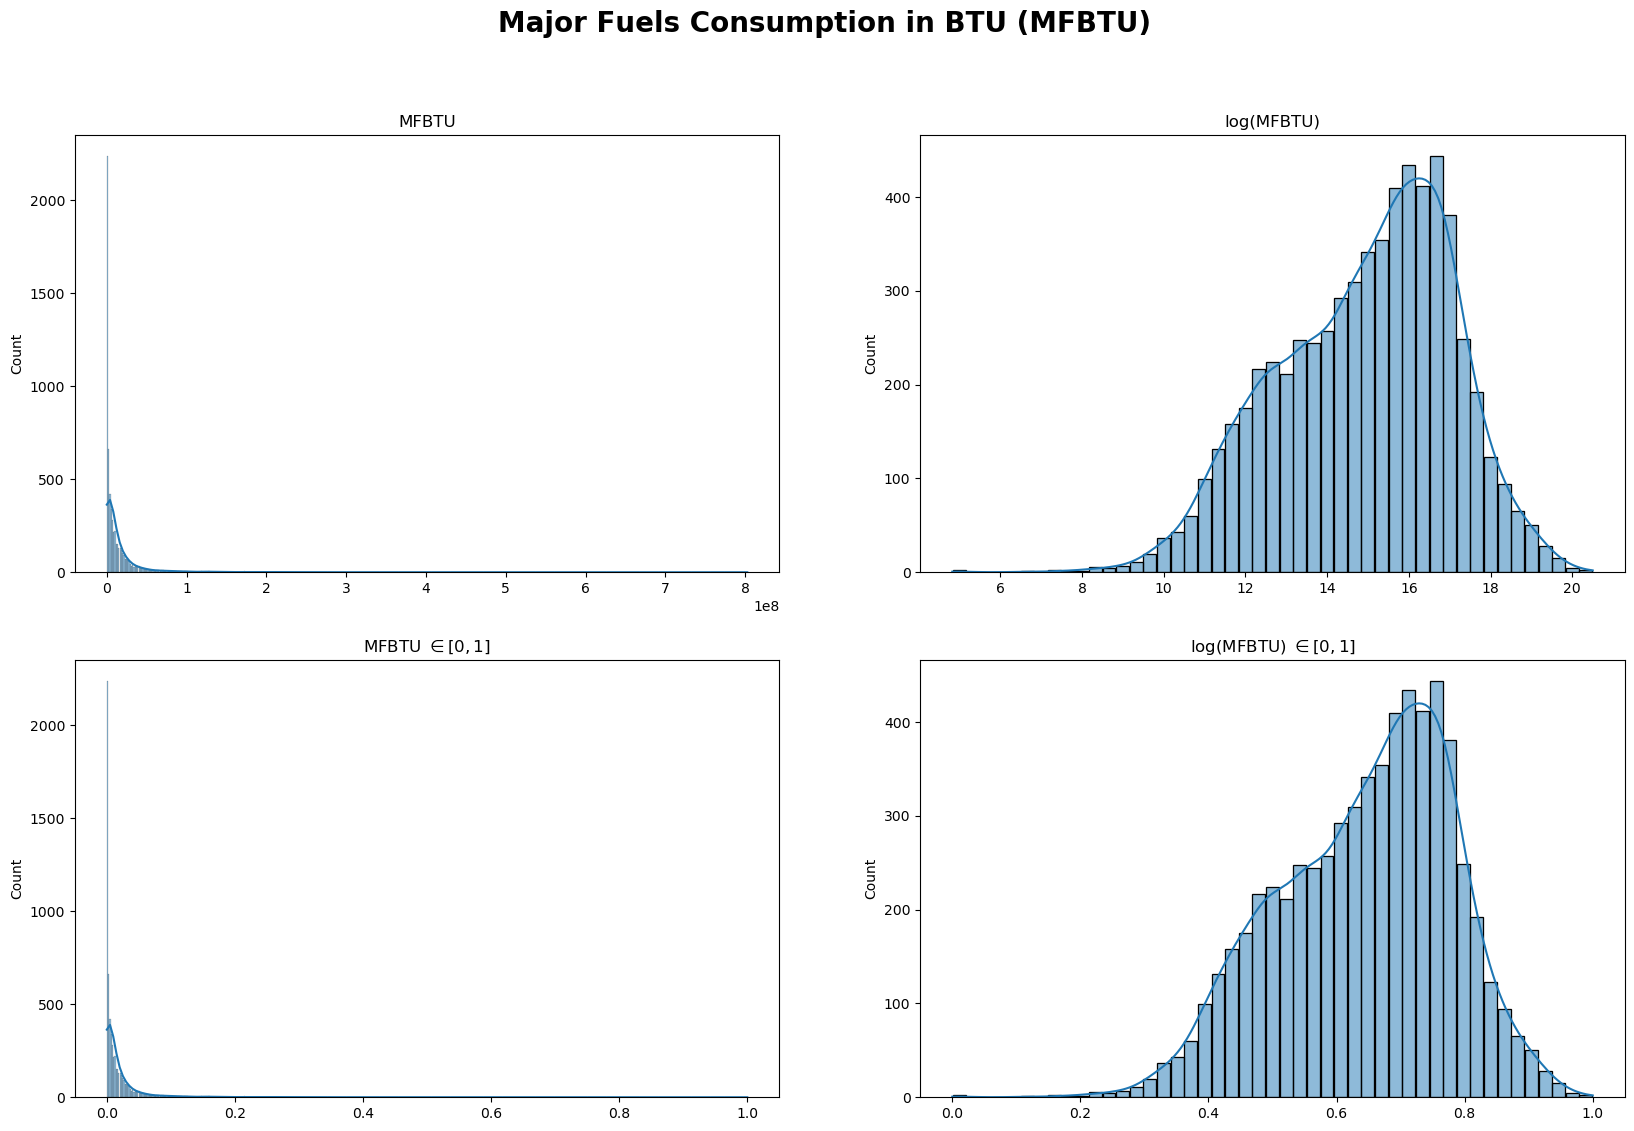

In [18]:
fig, axes = plt.subplots(2,2, figsize=(20,12.5))
axes = axes.ravel()

sns.histplot(y, ax=axes[0], shrink=.95, kde=True, legend=False)
sns.histplot(np.log(y), ax=axes[1], shrink=.95, kde=True, legend=False)
sns.histplot(pd.DataFrame(y_normalized, columns=['MFBTU']), ax=axes[2], shrink=.95, kde=True, legend=False)
sns.histplot(pd.DataFrame(y_log_normalized, columns=['MFBTU']), ax=axes[3], shrink=.95, kde=True, legend=False)


axes[0].set_title('MFBTU');
axes[1].set_title('log(MFBTU)');
axes[2].set_title('MFBTU $\in [0, 1]$');
axes[3].set_title('log(MFBTU) $\in [0, 1]$');
fig.suptitle('Major Fuels Consumption in BTU (MFBTU)', fontsize=20, fontweight='bold');

plt.savefig('../images/variables_mfbtu.png', dpi=300)

# **Test-Train Split according to Spatial Cross Validation**

We use spatial cross validation to make the testing and training datasets. Observations in the Middle Atlantic are kept out as a testing set. 

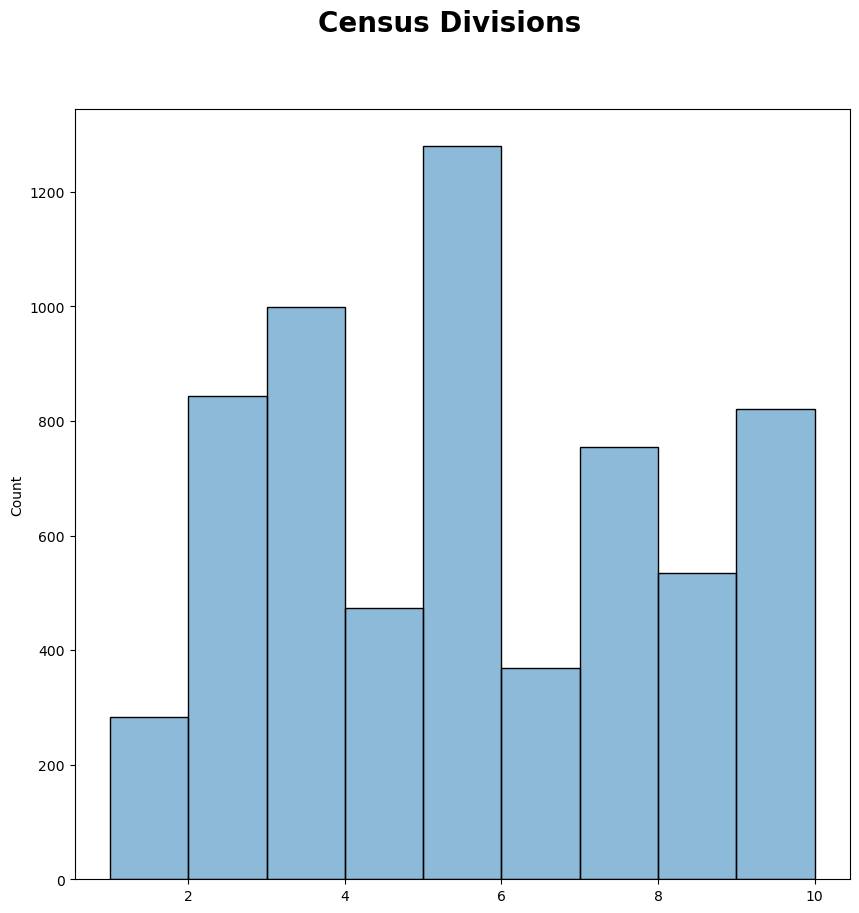

In [19]:
fig = plt.figure(figsize=(10,10))

sns.histplot(pd.DataFrame(divisions, columns=['Census Divisions']), legend=False, binrange=[1,10], binwidth=1);
fig.suptitle('Census Divisions', fontsize=20, fontweight='bold');

fig.savefig('../images/variables_censusdivisions.png', dpi=300)

In [20]:
X = df.copy()
X = X.astype(float)

X['divisions'] = divisions

X_train = X[X.divisions != 2]
y_train = y.iloc[X_train.index]

X_test = X[X.divisions == 2]
y_test = y.iloc[X_test.index]

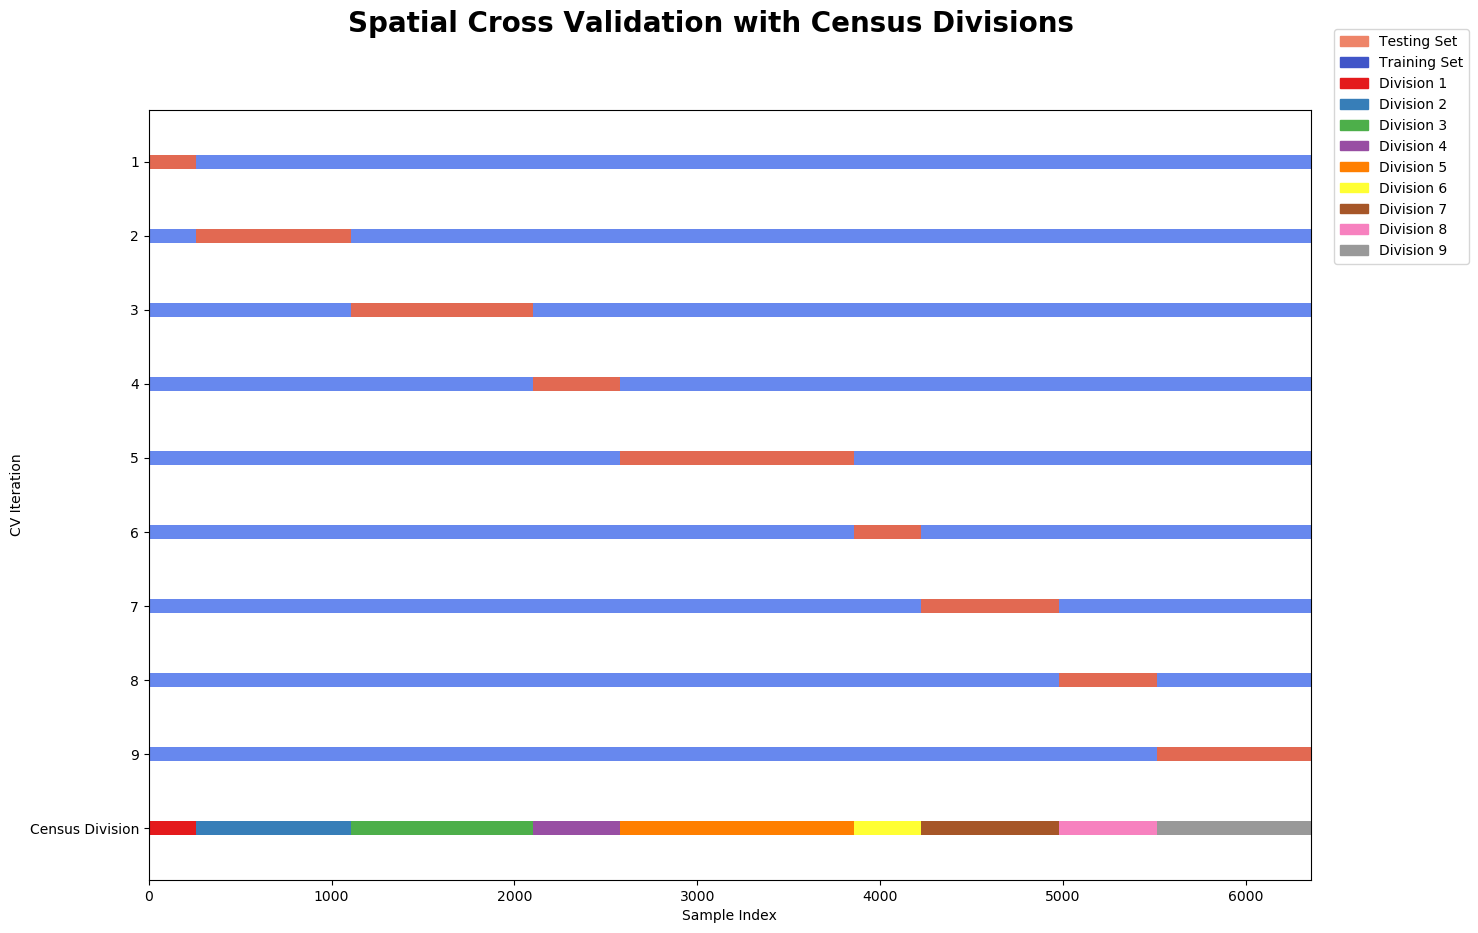

In [21]:
X_sorted_by_divisions = X.copy(deep=True)
X_sorted_by_divisions['MFBTU'] = y.values
X_sorted_by_divisions = X_sorted_by_divisions.sort_values(by='divisions', ascending=True)
divisions_sorted = X_sorted_by_divisions.divisions.tolist()

logo = LeaveOneGroupOut()

fig, ax = plt.subplots(figsize=(15,10))
for ii, (tr, tt) in enumerate(logo.split(X=X_sorted_by_divisions, y=X_sorted_by_divisions['MFBTU'], groups=divisions_sorted)):
    indices = np.array([np.nan] * len(X_sorted_by_divisions))
    indices[tt] = 1
    indices[tr] = 0

    ax.scatter(
        range(len(indices)),
        [ii + 0.5] * len(indices),
        c=indices,
        marker="_",
        lw=10,
        cmap=plt.cm.coolwarm,
        vmin=-0.2,
        vmax=1.2,
    )

    ax.scatter(
        range(len(X_sorted_by_divisions)), [ii + 1.5] * len(X_sorted_by_divisions), c=divisions_sorted, marker="_", lw=10, cmap=plt.cm.Set1
    )
    
    yticklabels = list(range(1, 10)) + ["Census Division"]
    ax.set(
        yticks=np.arange(9 + 1) + 0.5,
        yticklabels=yticklabels,
        xlabel="Sample Index",
        ylabel="CV Iteration",
        ylim=[9 + 1.2, -0.2],
        xlim=[0, len(X_sorted_by_divisions)],
    )
    
    ax.legend(
        [Patch(color=plt.cm.coolwarm(0.8)), Patch(color=plt.cm.coolwarm(0.02)),
         Patch(color=plt.cm.Set1(0)), Patch(color=plt.cm.Set1(1)),
         Patch(color=plt.cm.Set1(2)), Patch(color=plt.cm.Set1(3)),
         Patch(color=plt.cm.Set1(4)), Patch(color=plt.cm.Set1(5)),
         Patch(color=plt.cm.Set1(6)), Patch(color=plt.cm.Set1(7)),
         Patch(color=plt.cm.Set1(8)),],
        ["Testing Set", "Training Set",
         "Division 1", "Division 2",
         "Division 3", "Division 4",
         "Division 5", "Division 6",
         "Division 7", "Division 8",
         "Division 9",],
        loc=(1.02, 0.8),
    )

    
fig.suptitle('Spatial Cross Validation with Census Divisions', fontsize=20, fontweight='bold');
fig.savefig('../images/spatialcrossvalidation.png', dpi=300)

In [22]:
X = X.drop(columns=['divisions'])
X_train = X_train.drop(columns=['divisions'])
X_test = X_test.drop(columns=['divisions'])

#Since we have split everything up into different notebooks, we save these as CSVs.
X.to_csv('../data/X.csv', index=False)
y.to_csv('../data/y.csv', index=False)

X_train.to_csv('../data/X_train.csv', index=False)
y_train.to_csv('../data/y_train.csv', index=False)

X_test.to_csv('../data/X_test.csv', index=False)
y_test.to_csv('../data/y_test.csv', index=False)